# 07 — Final model comparison and held-out evaluation

This notebook summarizes earlier experiments with their evaluation procedures clearly labeled, then evaluates only the fixed Random Forest candidate from notebook 06 on the previously held-out test partition. The model and 0.50 threshold are checked against the saved tuning summary before the test data is opened; no retraining, tuning, or model switching occurs.

Positive class 1 means poisonous. A false negative—poisonous predicted edible—is the critical error to monitor. These observations are hypothetical and this educational model must never be used to decide whether real mushrooms are safe to eat.

## 1. Introduction and final evaluation objectives

Historical CV and holdout scores are not pooled into a single ranking because the experiments used different preprocessing and evaluation procedures. Final test results are reported separately as one held-out evaluation of the already selected candidate.

## 2. Imports and configuration

In [14]:
# Import libraries for artifact loading, metrics, uncertainty estimates, plots, and reporting.
from datetime import datetime, timezone
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import load
from scipy.stats import norm
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
import sklearn
import scipy
import pyarrow

# Locate the project root from the notebook's current directory or one of its parents.
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'mushroom' / 'preprocessing.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate mushroom/preprocessing.py from the notebook directory.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Centralize input/output locations so every later cell uses the same project paths.
DATA_DIR = PROJECT_ROOT / 'mushroom' / 'data'
FIGURE_DIR = DATA_DIR / 'figures'
MODEL_PATH = DATA_DIR / 'models' / 'tuned_mushroom_candidate.joblib'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
# Label 1 is poisonous throughout; keep this explicit for metrics and probability lookup.
POSITIVE_LABEL = 1
RANDOM_STATE = 42
N_BOOTSTRAP = 2000
plt.style.use('seaborn-v0_8-whitegrid')
print(f'Project: {PROJECT_ROOT}')
print(f'scikit-learn={sklearn.__version__}; pandas={pd.__version__}; scipy={scipy.__version__}; pyarrow={pyarrow.__version__}')

Project: /Users/hamidiqbal/ThomasMore/deep learning/AWS/cloud_AI_challenge/cloud-ai-avenue-5
scikit-learn=1.4.2; pandas=3.0.6; scipy=1.11.4; pyarrow=18.1.0


## 3. Load previous experiment results

Inspect and standardize the available CSVs without assuming their column names are identical. Missing false-negative counts remain empty when an earlier result file did not save predictions. The PyCaret comparison used a smaller internal CV subset and different preprocessing; its metrics are contextual, not directly equivalent.

In [15]:
# Load metadata and the final tuning record before examining any held-out test observations.
with (DATA_DIR / 'mushroom_preprocessing_metadata.json').open(encoding='utf-8') as file:
    preprocessing_metadata = json.load(file)
with (DATA_DIR / 'mushroom_tuning_summary.json').open(encoding='utf-8') as file:
    tuning_summary = json.load(file)

baseline_path = DATA_DIR / 'mushroom_baseline_results.csv'
pycaret_path = DATA_DIR / 'mushroom_pycaret_comparison.csv'
training_path = DATA_DIR / 'mushroom_model_training_results.csv'
tuning_path = DATA_DIR / 'mushroom_tuning_results.csv'
# Fail early if a historical result is unavailable instead of silently omitting that experiment.
for path in [baseline_path, pycaret_path, training_path, tuning_path]:
    if not path.is_file():
        raise FileNotFoundError(f'Required prior result file is missing: {path}')

baseline_df = pd.read_csv(baseline_path)
pycaret_df = pd.read_csv(pycaret_path)
training_df = pd.read_csv(training_path)
tuning_df = pd.read_csv(tuning_path)
# Print schemas because earlier notebooks use different naming conventions for the same metrics.
print('Available result schemas:')
for label, frame in [
    ('Baseline', baseline_df), ('PyCaret', pycaret_df),
    ('Model training', training_df), ('Nested tuning', tuning_df),
]:
    print(f'{label}: {frame.columns.tolist()}')

Available result schemas:
Baseline: ['Model', 'accuracy_mean', 'accuracy_std', 'balanced_accuracy_mean', 'balanced_accuracy_std', 'poisonous_precision_mean', 'poisonous_precision_std', 'poisonous_recall_mean', 'poisonous_recall_std', 'poisonous_f1_mean', 'poisonous_f1_std', 'roc_auc_mean', 'roc_auc_std']
PyCaret: ['Model', 'Accuracy', 'AUC', 'Recall', 'Prec.', 'F1', 'Kappa', 'MCC', 'Poisonous Recall', 'Balanced Accuracy', 'TT (Sec)']
Model training: ['Model', 'cv_fit_and_prediction_seconds', 'accuracy_mean', 'accuracy_std', 'balanced_accuracy_mean', 'balanced_accuracy_std', 'poisonous_precision_mean', 'poisonous_precision_std', 'poisonous_recall_mean', 'poisonous_recall_std', 'poisonous_f1_mean', 'poisonous_f1_std', 'roc_auc_mean', 'roc_auc_std', 'oof_true_negative', 'oof_false_positive', 'oof_false_negative', 'oof_true_positive', 'oof_false_negative_rate', 'oof_precision', 'oof_recall', 'oof_f1', 'oof_roc_auc']
Nested tuning: ['model', 'strategy', 'outer_folds', 'accuracy_mean', 'accu

## 4. Summarize historical model comparisons

Standardize rows for display and export, but preserve each method label. Baseline and training notebooks use shared-preprocessor 5-fold CV on all 4,000 training rows; PyCaret CV uses about 3,200 rows and distinct preprocessing; tuning uses nested outer CV. Historical values are not final-test results.

,experiment_stage,model,evaluation_method,accuracy,poisonous_recall,poisonous_precision,poisonous_f1,balanced_accuracy,roc_auc,false_negatives,false_negative_rate,notes
0,Baseline (03),Dummy — Most Frequent,"5-fold stratified CV; all 4,000 training rows;...",0.62150,0.000000,0.000000,0.000000,0.500000,0.500000,NaN,NaN,
1,Baseline (03),Dummy — Stratified,"5-fold stratified CV; all 4,000 training rows;...",0.53250,0.381105,0.382119,0.381611,0.502903,0.502903,NaN,NaN,
2,Baseline (03),Logistic Regression,"5-fold stratified CV; all 4,000 training rows;...",0.69600,0.347418,0.699075,0.463269,0.627851,0.688199,NaN,NaN,
3,PyCaret (04),Decision Tree Classifier,"PyCaret internal CV; ~3,200-row internal train...",0.71370,0.614400,0.624900,0.618700,0.694300,0.694300,NaN,NaN,Exploratory; internal holdout/split differs fr...
4,PyCaret (04),Light Gradient Boosting Machine,"PyCaret internal CV; ~3,200-row internal train...",0.77030,0.571500,0.761800,0.652800,0.731400,0.796800,NaN,NaN,Exploratory; internal holdout/split differs fr...
5,PyCaret (04),Random Forest Classifier,"PyCaret internal CV; ~3,200-row internal train...",0.77870,0.560700,0.794500,0.656600,0.736100,0.811200,NaN,NaN,Exploratory; internal holdout/split differs fr...
6,PyCaret (04),Extra Trees Classifier,"PyCaret internal CV; ~3,200-row internal train...",0.74000,0.558200,0.695500,0.617800,0.704500,0.777400,NaN,NaN,Exploratory; internal holdout/split differs fr...
7,PyCaret (04),K Neighbors Classifier,"PyCaret internal CV; ~3,200-row internal train...",0.73880,0.518600,0.713300,0.599400,0.695700,0.743600,NaN,NaN,Exploratory; internal holdout/split differs fr...
8,PyCaret (04),Gradient Boosting Classifier,"PyCaret internal CV; ~3,200-row internal train...",0.74500,0.426100,0.811100,0.557600,0.682600,0.763500,NaN,NaN,Exploratory; internal holdout/split differs fr...
9,PyCaret (04),SVM - Radial Kernel,"PyCaret internal CV; ~3,200-row internal train...",0.74030,0.403800,0.818700,0.539900,0.674500,0.742400,NaN,NaN,Exploratory; internal holdout/split differs fr...


These rows summarize distinct experiments; do not rank or interpret them as one common test set.


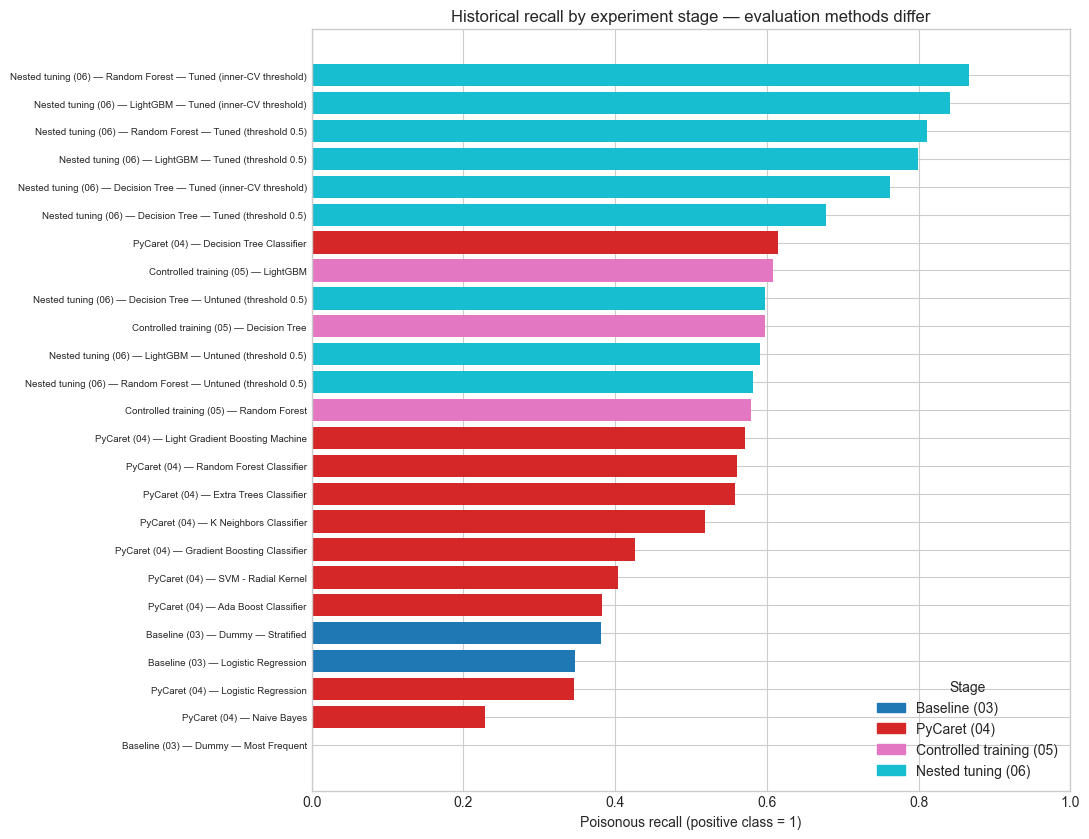

In [16]:
# Build a common row format while preserving the original experiment stage and method.
history_rows = []

# Map whichever metric columns exist in a source table into the shared comparison schema.
def add_cv_history(frame, stage, evaluation_method, model_column='Model',
                   metric_columns=None, false_negative_column=None, notes=''):
    metric_columns = metric_columns or {}
    for _, row in frame.iterrows():
        # Initialize unavailable statistics as NaN so missing historical evidence stays explicit.
        record = {
            'experiment_stage': stage,
            'model': row[model_column],
            'evaluation_method': evaluation_method,
            'accuracy': np.nan,
            'poisonous_recall': np.nan,
            'poisonous_precision': np.nan,
            'poisonous_f1': np.nan,
            'balanced_accuracy': np.nan,
            'roc_auc': np.nan,
            'false_negatives': np.nan,
            'false_negative_rate': np.nan,
            'notes': notes,
        }
        # Convert only metrics actually present in the source result row.
        for standard_name, source_name in metric_columns.items():
            if source_name in row.index and pd.notna(row[source_name]):
                record[standard_name] = float(row[source_name])
        if false_negative_column and false_negative_column in row.index and pd.notna(row[false_negative_column]):
            record['false_negatives'] = int(row[false_negative_column])
        history_rows.append(record)

# Baseline and controlled-training result files share the same metric column names.
baseline_metric_columns = {
    'accuracy': 'accuracy_mean',
    'poisonous_recall': 'poisonous_recall_mean',
    'poisonous_precision': 'poisonous_precision_mean',
    'poisonous_f1': 'poisonous_f1_mean',
    'balanced_accuracy': 'balanced_accuracy_mean',
    'roc_auc': 'roc_auc_mean',
}
add_cv_history(
    baseline_df, 'Baseline (03)',
    '5-fold stratified CV; all 4,000 training rows; shared preprocessing',
    metric_columns=baseline_metric_columns,
)

# PyCaret exports display-oriented names, so map them separately rather than assuming equivalence.
pycaret_columns = {
    'accuracy': 'Accuracy',
    'poisonous_recall': 'Poisonous Recall',
    'poisonous_precision': 'Prec.',
    'poisonous_f1': 'F1',
    'balanced_accuracy': 'Balanced Accuracy',
    'roc_auc': 'AUC',
}
add_cv_history(
    pycaret_df, 'PyCaret (04)',
    'PyCaret internal CV; ~3,200-row internal training subset; different preprocessing',
    metric_columns=pycaret_columns,
    notes='Exploratory; internal holdout/split differs from other stages.',
)

# Validate the required identifier before standardizing controlled-training results.
if 'Model' not in training_df.columns:
    raise ValueError('Expected Model column in model-training results.')
add_cv_history(
    training_df, 'Controlled training (05)',
    '5-fold stratified CV; all 4,000 training rows; shared preprocessing',
    metric_columns=baseline_metric_columns,
    false_negative_column='oof_false_negative',
)

# Keep the tuning schema documented; its pooled outer-fold values need explicit mapping below.
tuning_metric_columns = {
    'accuracy': 'accuracy_mean',
    'poisonous_recall': 'pooled_outer_poisonous_recall',
    'poisonous_precision': 'pooled_outer_poisonous_precision',
    'poisonous_f1': 'pooled_outer_poisonous_f1',
    'balanced_accuracy': 'pooled_outer_balanced_accuracy',
    'roc_auc': 'pooled_outer_roc_auc',
}
# Nested-CV metrics come from pooled outer-fold predictions, with threshold choice confined to inner CV.
for _, row in tuning_df.iterrows():
    history_rows.append({
        'experiment_stage': 'Nested tuning (06)',
        'model': row['model'] + ' — ' + row['strategy'],
        'evaluation_method': '5-fold nested CV; pooled outer-fold predictions; threshold selected in inner CV',
        'accuracy': float(row['accuracy_mean']),
        'poisonous_recall': float(row['pooled_outer_poisonous_recall']),
        'poisonous_precision': float(row['pooled_outer_poisonous_precision']),
        'poisonous_f1': float(row['pooled_outer_poisonous_f1']),
        'balanced_accuracy': float(row['pooled_outer_balanced_accuracy']),
        'roc_auc': float(row['pooled_outer_roc_auc']),
        'false_negatives': int(row['pooled_outer_false_negatives']),
        'false_negative_rate': float(row['pooled_outer_false_negative_rate']),
        'notes': f'Outer-CV strategy: {row["strategy"]}; thresholds={row["thresholds_by_outer_fold"]}',
    })

# This comparison is contextual because its rows come from distinct evaluation procedures.
historical_comparison_df = pd.DataFrame(history_rows)
display(historical_comparison_df)
print('These rows summarize distinct experiments; do not rank or interpret them as one common test set.')

# Plot poisonous recall only where a source experiment recorded it; do not imply common test conditions.
plot_history = historical_comparison_df.dropna(subset=['poisonous_recall']).copy()
stage_order = list(plot_history['experiment_stage'].drop_duplicates())
stage_colors = dict(zip(stage_order, plt.cm.tab10(np.linspace(0, 1, len(stage_order)))))
plot_history['plot_label'] = plot_history['experiment_stage'] + ' — ' + plot_history['model']
plot_history = plot_history.sort_values('poisonous_recall')
fig, ax = plt.subplots(figsize=(11, max(7, 0.34 * len(plot_history))))
ax.barh(
    plot_history['plot_label'],
    plot_history['poisonous_recall'],
    color=[stage_colors[stage] for stage in plot_history['experiment_stage']],
)
ax.set_xlim(0, 1)
ax.set_xlabel('Poisonous recall (positive class = 1)')
ax.set_title('Historical recall by experiment stage — evaluation methods differ')
ax.tick_params(axis='y', labelsize=7)
handles = [
    plt.Rectangle((0, 0), 1, 1, color=stage_colors[stage], label=stage)
    for stage in stage_order
]
ax.legend(handles=handles, title='Stage')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '07_historical_model_comparison.png', dpi=170)
# Close after the explicit display to prevent the notebook backend rendering the figure again.
plt.show()
plt.close(fig)

## 5. Load and validate the selected model artifact

Load and inspect the bundle before loading test data. Compare the estimator identity, required hyperparameters, target mapping, and threshold against the tuning summary. If any expected value differs, stop rather than substituting or repairing the artifact.

In [17]:
# Load the candidate bundle and confirm its identity before opening the held-out partition.
if not MODEL_PATH.is_file():
    raise FileNotFoundError(f'Selected model artifact is missing: {MODEL_PATH}')
candidate_bundle = load(MODEL_PATH)
if not isinstance(candidate_bundle, dict) or not {'pipeline', 'threshold', 'selected_model'} <= set(candidate_bundle):
    raise TypeError('Expected a saved candidate bundle with pipeline, threshold, and selected_model fields.')
pipeline = candidate_bundle['pipeline']
threshold = float(candidate_bundle['threshold'])
selected_model = candidate_bundle['selected_model']
if selected_model != 'Random Forest' or tuning_summary['selection_rule']['selected_model'] != 'Random Forest':
    raise ValueError('Saved candidate identity disagrees with the required selected Random Forest.')
if not hasattr(pipeline, 'named_steps') or 'preprocessor' not in pipeline.named_steps or 'classifier' not in pipeline.named_steps:
    raise TypeError('Saved candidate must contain the complete preprocessing and classifier pipeline.')
# Inspect the classifier inside the saved end-to-end pipeline, without refitting it.
classifier = pipeline.named_steps['classifier']
params = classifier.get_params()
expected_params = {
    'n_estimators': 250,
    'max_depth': 20,
    'min_samples_leaf': 4,
    'min_samples_split': 2,
    'max_features': 'sqrt',
    'class_weight': {0: 1, 1: 3},
}
actual_params = {key: params.get(key) for key in expected_params}
if actual_params != expected_params:
    raise ValueError(f'Saved estimator parameters disagree with the approved candidate: {actual_params}')
# Check that the saved estimator agrees with the tuning notebook's final training-only refit.
summary_refit = tuning_summary.get('final_training_only_refit') or {}
summary_params = summary_refit.get('best_params', {})
for key, expected in expected_params.items():
    summary_key = f'classifier__{key}'
    observed = summary_params.get(summary_key)
    if key == 'class_weight' and isinstance(observed, dict):
        observed = {int(weight_key): weight_value for weight_key, weight_value in observed.items()}
    if observed != expected:
        raise ValueError(f'Tuning summary parameter {summary_key}={observed!r}, expected {expected!r}.')
# Require the approved threshold exactly; do not revise it based on test performance.
if abs(threshold - 0.50) > 1e-12 or abs(float(summary_refit.get('threshold', np.nan)) - threshold) > 1e-12:
    raise ValueError('Saved threshold disagrees with the approved 0.50 candidate and tuning summary.')
if set(classifier.classes_) != {0, 1}:
    raise ValueError(f'Expected classifier classes [0, 1], got {classifier.classes_}.')
if candidate_bundle.get('positive_label') != POSITIVE_LABEL:
    raise ValueError('Saved candidate positive label is not poisonous class 1.')
print(f'Validated artifact: {selected_model}; threshold={threshold:.2f}; classes={classifier.classes_.tolist()}')
print(f'Validated hyperparameters: {actual_params}')
print(f'Bundle fields: {sorted(candidate_bundle)}')

Validated artifact: Random Forest; threshold=0.50; classes=[0, 1]
Validated hyperparameters: {'n_estimators': 250, 'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 2, 'max_features': 'sqrt', 'class_weight': {0: 1, 1: 3}}
Bundle fields: ['note', 'pipeline', 'positive_label', 'positive_label_name', 'selected_model', 'selection_rule', 'threshold']


## 6. Load the untouched test data

Only after confirming the fixed candidate do we open the existing test partition. Check shape, column order, binary labels, metadata mapping, missing values, and training/test feature-row overlap where exact row hashing is available. Any overlap is reported without modifying the supplied test set.

In [18]:
# Load the saved training features only for schema and overlap checks, plus the untouched test partition.
X_train_check = pd.read_parquet(DATA_DIR / 'mushroom_X_train_raw.parquet')
y_train_check = pd.read_parquet(DATA_DIR / 'mushroom_y_train.parquet').iloc[:, 0]
X_test = pd.read_parquet(DATA_DIR / 'mushroom_X_test_raw.parquet')
y_test_frame = pd.read_parquet(DATA_DIR / 'mushroom_y_test.parquet')
if y_test_frame.shape[1] != 1:
    raise ValueError(f'Expected one test target column; got {y_test_frame.shape[1]}.')
y_test = y_test_frame.iloc[:, 0].rename('class')
# Enforce the exact input schema expected by the fitted preprocessor.
expected_columns = preprocessing_metadata['raw_feature_order']
if X_train_check.columns.tolist() != expected_columns or X_test.columns.tolist() != expected_columns:
    raise ValueError('Training or test feature names/order disagree with preprocessing metadata.')
if len(X_test) != len(y_test) or len(X_test) != preprocessing_metadata['n_test_rows']:
    raise ValueError(f'Test rows/labels do not align with expected size {preprocessing_metadata["n_test_rows"]}.')
if len(X_train_check) != len(y_train_check) or len(X_train_check) != preprocessing_metadata['n_training_rows']:
    raise ValueError('Training row counts disagree with preprocessing metadata.')
if set(y_test.unique()) != {0, 1} or set(y_train_check.unique()) != {0, 1}:
    raise ValueError('Train/test targets must both contain only 0 and 1.')
if preprocessing_metadata['target_mapping'] != {'e': 0, 'p': 1}:
    raise ValueError('Preprocessing metadata does not specify the expected class mapping.')
if list(pipeline.feature_names_in_) != expected_columns:
    raise ValueError('Saved pipeline feature schema does not match the supplied train/test feature order.')

# Hash rows first to make exact overlap checking efficient; equality confirms hash matches.
train_hashes = pd.util.hash_pandas_object(X_train_check.astype(object), index=False)
test_hashes = pd.util.hash_pandas_object(X_test.astype(object), index=False)
# Keep every training row position for each hash in case duplicate rows exist.
train_positions_by_hash = {}
for position, row_hash in enumerate(train_hashes):
    train_positions_by_hash.setdefault(int(row_hash), []).append(position)
# Report exact feature duplicates across partitions without altering either saved dataset.
overlap_pairs = []
for test_position, row_hash in enumerate(test_hashes):
    for train_position in train_positions_by_hash.get(int(row_hash), []):
        if X_train_check.iloc[train_position].equals(X_test.iloc[test_position]):
            overlap_pairs.append((train_position, test_position, int(y_train_check.iloc[train_position]), int(y_test.iloc[test_position])))
print(f'Test shape: {X_test.shape}; class counts: {y_test.value_counts().sort_index().to_dict()}')
print(f'Test missing feature cells: {int(X_test.isna().sum().sum()):,}')
print(f'Exact feature-row overlaps across saved train/test partitions: {len(overlap_pairs)}')
if overlap_pairs:
    print('Overlapping row indices and labels (no rows are removed):', overlap_pairs)
    same_label_overlaps = sum(train_label == test_label for _, _, train_label, test_label in overlap_pairs)
    print(f'Overlaps with matching labels: {same_label_overlaps}; this is a dataset-split limitation to disclose.')

Test shape: (1000, 10); class counts: {0: 621, 1: 379}
Test missing feature cells: 3,135
Exact feature-row overlaps across saved train/test partitions: 1
Overlapping row indices and labels (no rows are removed): [(3, 58, 1, 1)]
Overlaps with matching labels: 1; this is a dataset-split limitation to disclose.


## 7. Generate final predictions

The saved pipeline is used as-is. Determine the poisonous probability column from the fitted classifier's classes, then apply the saved 0.50 threshold using the same strict-greater-than convention documented in notebook 06. No test prediction is used to change the model or threshold.

In [19]:
# Locate the poisonous probability by its class label; never assume probability-column order.
classes = np.asarray(classifier.classes_)
positive_positions = np.flatnonzero(classes == POSITIVE_LABEL)
if len(positive_positions) != 1:
    raise ValueError(f'Cannot uniquely locate poisonous class {POSITIVE_LABEL} in {classes}.')
positive_index = int(positive_positions[0])
# Predict probabilities with the stored pipeline and apply its unchanged strict threshold rule.
test_probabilities = pipeline.predict_proba(X_test)[:, positive_index]
test_predictions = (test_probabilities > threshold).astype(int)
print(f'Predictions generated for {len(test_predictions)} held-out test observations.')
print(f'Fixed positive class: {POSITIVE_LABEL}; saved threshold: {threshold:.2f}; positive probability column: {positive_index}.')

Predictions generated for 1000 held-out test observations.
Fixed positive class: 1; saved threshold: 0.50; positive probability column: 1.


## 8. Calculate final test metrics

Compute each score once at the saved operating threshold. ROC-AUC and average precision summarize threshold-independent ranking behavior; confusion counts and recall describe this fixed threshold. False-negative rate is FN/(FN+TP); false-positive rate is FP/(FP+TN).

In [20]:
# Use fixed-threshold predictions to calculate confusion counts and class-sensitive metrics.
test_confusion = confusion_matrix(y_test, test_predictions, labels=[0, 1])
tn, fp, fn, tp = (int(value) for value in test_confusion.ravel())
# Keep positive-class metrics explicit; the denominator for FNR is all actual poisonous examples.
test_metrics = {
    'accuracy': float(accuracy_score(y_test, test_predictions)),
    'balanced_accuracy': float(balanced_accuracy_score(y_test, test_predictions)),
    'poisonous_recall': float(recall_score(y_test, test_predictions, pos_label=1, zero_division=0)),
    'poisonous_precision': float(precision_score(y_test, test_predictions, pos_label=1, zero_division=0)),
    'poisonous_f1': float(f1_score(y_test, test_predictions, pos_label=1, zero_division=0)),
    'roc_auc': float(roc_auc_score(y_test, test_probabilities)),
    'average_precision': float(average_precision_score(y_test, test_probabilities, pos_label=1)),
    'false_negatives': fn,
    'false_negative_rate': float(fn / (fn + tp)) if fn + tp else float('nan'),
    'false_positives': fp,
    'false_positive_rate': float(fp / (fp + tn)) if fp + tn else float('nan'),
    'true_positives': tp,
    'true_negatives': tn,
}
display(pd.Series(test_metrics, name='final_test_value').to_frame())
print(f'Positive (poisonous) test support: {int((y_test == 1).sum())}; FN={fn}; FNR={test_metrics["false_negative_rate"]:.4f}.')

,final_test_value
accuracy,0.684000
balanced_accuracy,0.719866
poisonous_recall,0.868074
poisonous_precision,0.552941
poisonous_f1,0.675565
roc_auc,0.835664
average_precision,0.784748
false_negatives,50.000000
false_negative_rate,0.131926
false_positives,266.000000


Positive (poisonous) test support: 379; FN=50; FNR=0.1319.


## 9. Confusion matrix analysis

Rows are actual labels and columns are predictions. TN/FP are the edible row; FN/TP are the poisonous row. The observed false negatives are poisonous test observations the model predicted edible—the most critical error in this educational evaluation, but not a real-world safety estimate.

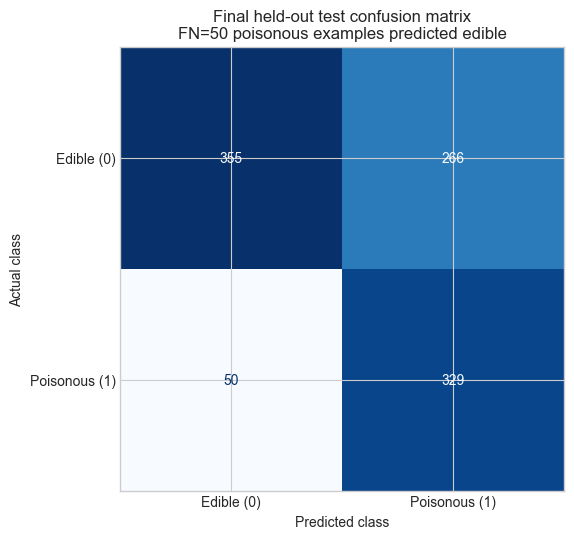

TN=355: edible correctly predicted edible
FP=266: edible incorrectly predicted poisonous
FN=50: poisonous incorrectly predicted edible
TP=329: poisonous correctly predicted poisonous
A false negative can create a misleading edible prediction; this model is not suitable for real mushroom safety decisions.


In [21]:
# Plot one confusion matrix from the fixed test predictions; rows are actual labels.
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(
    confusion_matrix=test_confusion,
    display_labels=['Edible (0)', 'Poisonous (1)'],
).plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_xlabel('Predicted class')
ax.set_ylabel('Actual class')
ax.set_title(f'Final held-out test confusion matrix\nFN={fn} poisonous examples predicted edible')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '07_final_test_confusion_matrix.png', dpi=170)
# Explicit display followed by close avoids a second inline-backend rendering.
plt.show()
plt.close(fig)
print(f'TN={tn}: edible correctly predicted edible')
print(f'FP={fp}: edible incorrectly predicted poisonous')
print(f'FN={fn}: poisonous incorrectly predicted edible')
print(f'TP={tp}: poisonous correctly predicted poisonous')
print('A false negative can create a misleading edible prediction; this model is not suitable for real mushroom safety decisions.')

## 10. ROC and precision–recall analysis

ROC-AUC measures ranking discrimination over possible thresholds. Average precision summarizes the precision–recall curve. Neither metric chooses a new operating point here; confusion matrix and recall reflect only the saved 0.50 threshold.

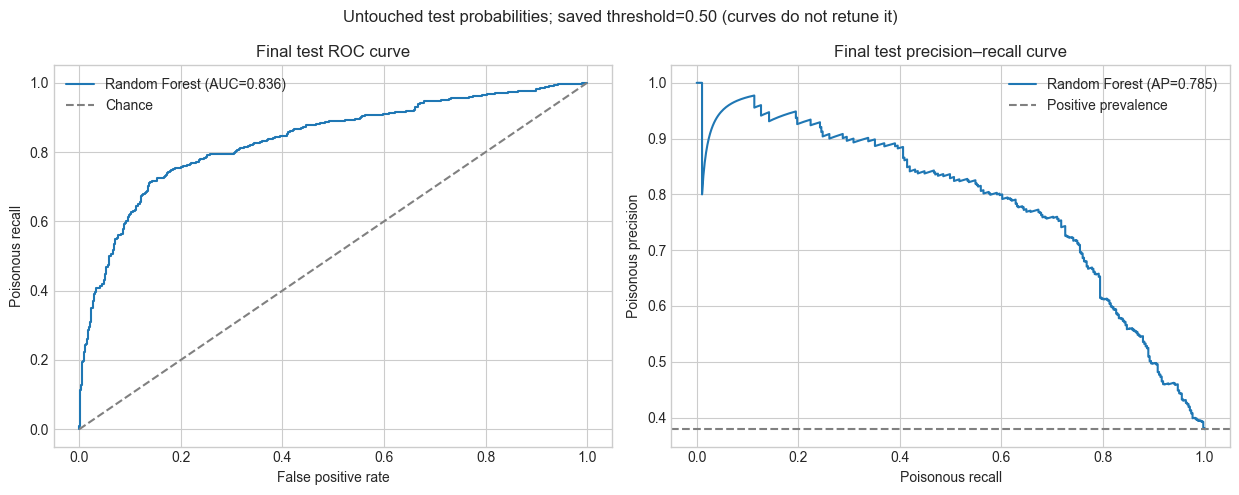

Final test ROC-AUC=0.8357; average precision=0.7847.


In [22]:
# Curves use the saved model's test probabilities and do not search for a new threshold.
fpr_curve, tpr_curve, _ = roc_curve(y_test, test_probabilities, pos_label=1)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probabilities, pos_label=1)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
axes[0].plot(fpr_curve, tpr_curve, label=f'Random Forest (AUC={test_metrics["roc_auc"]:.3f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
axes[0].set(xlabel='False positive rate', ylabel='Poisonous recall', title='Final test ROC curve')
axes[0].legend()
axes[1].plot(recall_curve, precision_curve, label=f'Random Forest (AP={test_metrics["average_precision"]:.3f})')
# Positive prevalence is the no-skill precision reference for this test partition.
axes[1].axhline((y_test == 1).mean(), linestyle='--', color='gray', label='Positive prevalence')
axes[1].set(xlabel='Poisonous recall', ylabel='Poisonous precision', title='Final test precision–recall curve')
axes[1].legend()
fig.suptitle(f'Untouched test probabilities; saved threshold={threshold:.2f} (curves do not retune it)')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '07_final_test_roc_pr_curves.png', dpi=170)
# Close after display so the combined ROC/PR figure is emitted once.
plt.show()
plt.close(fig)
print(f'Final test ROC-AUC={test_metrics["roc_auc"]:.4f}; average precision={test_metrics["average_precision"]:.4f}.')

## 11. Compare nested CV with test performance

Compare the selected Random Forest's pooled nested outer-fold results at its inner-selected thresholds with this final held-out test result. Nested outer-fold models trained on about 3,200 observations per fold; the saved candidate was fitted on all 4,000 training rows. Treat small differences cautiously. Do not compare raw FN counts across 4,000 OOF versus 1,000 test rows; compare rates instead.

,metric,nested_outer_cv,final_test,test_minus_nested_cv
0,poisonous_recall,0.866579,0.868074,0.001495
1,poisonous_precision,0.518372,0.552941,0.034569
2,poisonous_f1,0.648702,0.675565,0.026863
3,balanced_accuracy,0.688116,0.719866,0.031750
4,roc_auc,0.809788,0.835664,0.025876


Nested-CV FNR=0.1334 (202/4000 out-of-fold rows); final test FNR=0.1319 (50/1000 test rows; 379 poisonous test examples).


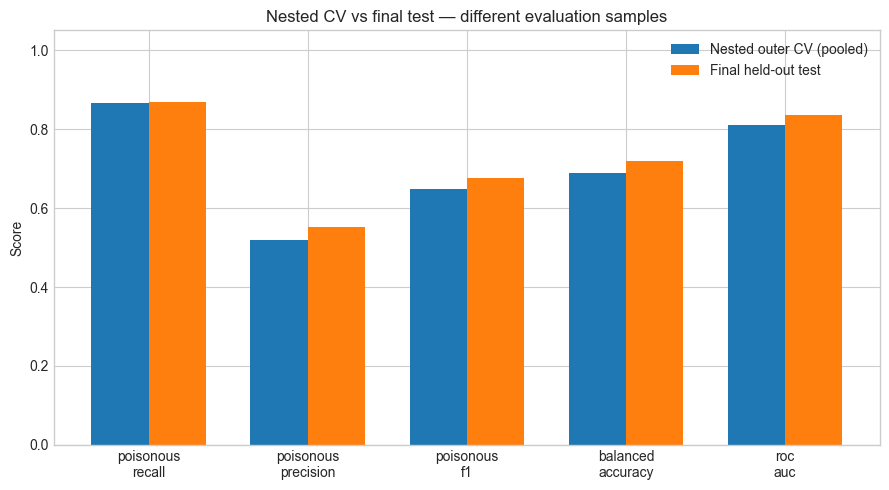

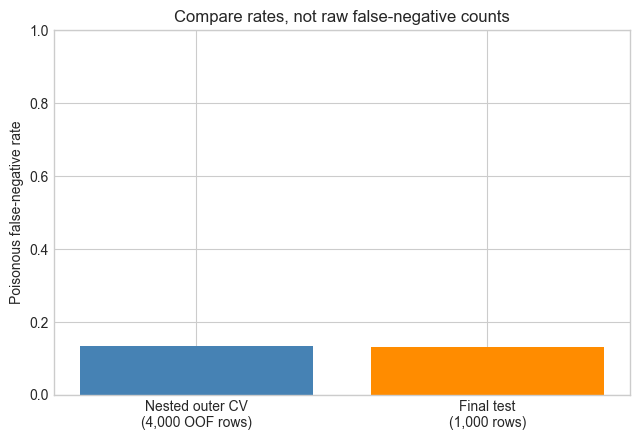

In [23]:
# Retrieve only the tuned-threshold Random Forest summary from notebook 06 for context.
tuned_outer = tuning_df[
    (tuning_df['model'] == 'Random Forest')
    & (tuning_df['strategy'] == 'Tuned (inner-CV threshold)')
]
if len(tuned_outer) != 1:
    raise ValueError('Expected exactly one nested outer-CV Random Forest tuned-threshold summary.')
tuned_outer = tuned_outer.iloc[0]
# These pooled nested-CV values describe OOF rows, not the final fitted candidate or test partition.
cv_reference = {
    'poisonous_recall': float(tuned_outer['pooled_outer_poisonous_recall']),
    'poisonous_precision': float(tuned_outer['pooled_outer_poisonous_precision']),
    'poisonous_f1': float(tuned_outer['pooled_outer_poisonous_f1']),
    'balanced_accuracy': float(tuned_outer['pooled_outer_balanced_accuracy']),
    'roc_auc': float(tuned_outer['pooled_outer_roc_auc']),
    'false_negative_rate': float(tuned_outer['pooled_outer_false_negative_rate']),
    'false_negatives': int(tuned_outer['pooled_outer_false_negatives']),
    'evaluation_rows': int(len(X_train_check)),
}
comparison_metrics = ['poisonous_recall', 'poisonous_precision', 'poisonous_f1', 'balanced_accuracy', 'roc_auc']
# Compare score differences, but interpret them cautiously because training/evaluation samples differ.
validation_test_rows = []
for metric in comparison_metrics:
    validation_test_rows.append({
        'metric': metric,
        'nested_outer_cv': cv_reference[metric],
        'final_test': test_metrics[metric],
        'test_minus_nested_cv': test_metrics[metric] - cv_reference[metric],
    })
validation_test_df = pd.DataFrame(validation_test_rows)
display(validation_test_df)
print(
    f'Nested-CV FNR={cv_reference["false_negative_rate"]:.4f} '
    f'({cv_reference["false_negatives"]}/{cv_reference["evaluation_rows"]} out-of-fold rows); '
    f'final test FNR={test_metrics["false_negative_rate"]:.4f} '
    f'({fn}/{len(X_test)} test rows; {int((y_test == 1).sum())} poisonous test examples).'
)

# Show performance rates side by side; do not compare raw FN counts across different row totals.
fig, ax = plt.subplots(figsize=(9, 5))
plot_metrics = ['poisonous_recall', 'poisonous_precision', 'poisonous_f1', 'balanced_accuracy', 'roc_auc']
x = np.arange(len(plot_metrics))
width = 0.36
cv_values = [cv_reference[metric] for metric in plot_metrics]
test_values = [test_metrics[metric] for metric in plot_metrics]
ax.bar(x - width / 2, cv_values, width, label='Nested outer CV (pooled)')
ax.bar(x + width / 2, test_values, width, label='Final held-out test')
ax.set_xticks(x, [metric.replace('_', '\n') for metric in plot_metrics])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Nested CV vs final test — different evaluation samples')
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / '07_nested_cv_vs_final_test.png', dpi=170)
# Close after explicit display to avoid duplicate rendering in the notebook output.
plt.show()
plt.close(fig)

# Compare false-negative rates (not counts) because the OOF and test sets have different sizes.
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.bar(['Nested outer CV\n(4,000 OOF rows)', 'Final test\n(1,000 rows)'],
       [cv_reference['false_negative_rate'], test_metrics['false_negative_rate']],
       color=['steelblue', 'darkorange'])
ax.set_ylim(0, 1)
ax.set_ylabel('Poisonous false-negative rate')
ax.set_title('Compare rates, not raw false-negative counts')
fig.tight_layout()
fig.savefig(FIGURE_DIR / '07_false_negative_rate_comparison.png', dpi=170)
plt.show()
plt.close(fig)

## 12. Confidence intervals and limitations

Use Wilson binomial intervals for poisonous recall and precision, based on their class-specific denominators. Use class-stratified bootstrap intervals for balanced accuracy and ROC-AUC. These intervals quantify sampling uncertainty under this test sample; they are not proof of safety or of performance on different populations.

In [24]:
# Wilson intervals suit binomial proportions such as recall and precision.
def wilson_interval(successes, total, confidence=0.95):
    if total <= 0:
        return [float('nan'), float('nan')]
    z = float(norm.ppf(0.5 + confidence / 2))
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    half_width = z * np.sqrt(proportion * (1 - proportion) / total + z**2 / (4 * total**2)) / denominator
    return [float(center - half_width), float(center + half_width)]

# Use actual poisonous support for recall and predicted-poisonous support for precision.
poisonous_test_count = int((y_test == 1).sum())
confidence_intervals = {
    'poisonous_recall_wilson_95pct': wilson_interval(tp, tp + fn),
    'poisonous_precision_wilson_95pct': wilson_interval(tp, tp + fp),
}
# Stratify bootstrap resampling by true class so every replicate contains both classes.
rng = np.random.default_rng(RANDOM_STATE)
negative_indices = np.flatnonzero(np.asarray(y_test) == 0)
positive_indices = np.flatnonzero(np.asarray(y_test) == 1)
bootstrap_balanced_accuracy = []
bootstrap_roc_auc = []
# Recompute balanced accuracy and ranking AUC across bootstrap samples for uncertainty ranges.
for _ in range(N_BOOTSTRAP):
    sample_indices = np.concatenate([
        rng.choice(negative_indices, size=len(negative_indices), replace=True),
        rng.choice(positive_indices, size=len(positive_indices), replace=True),
    ])
    sampled_y = np.asarray(y_test)[sample_indices]
    sampled_prediction = test_predictions[sample_indices]
    sampled_probability = test_probabilities[sample_indices]
    bootstrap_balanced_accuracy.append(balanced_accuracy_score(sampled_y, sampled_prediction))
    bootstrap_roc_auc.append(roc_auc_score(sampled_y, sampled_probability))
# Percentile bounds summarize bootstrap variability; they do not guarantee future performance.
confidence_intervals['balanced_accuracy_stratified_bootstrap_95pct'] = [
    float(value) for value in np.percentile(bootstrap_balanced_accuracy, [2.5, 97.5])
]
confidence_intervals['roc_auc_stratified_bootstrap_95pct'] = [
    float(value) for value in np.percentile(bootstrap_roc_auc, [2.5, 97.5])
]
display(pd.DataFrame([
    {'metric': metric, 'estimate': test_metrics[
         metric.replace('_wilson_95pct', '').replace('_stratified_bootstrap_95pct', '')
     ], 'ci_95_low': bounds[0], 'ci_95_high': bounds[1],
     'method': 'Wilson binomial' if 'wilson' in metric else 'Stratified bootstrap'}
    for metric, bounds in confidence_intervals.items()
]))
print(
    'Limitations: 5,000 hypothetical observations; missing values are substantial in multiple features; '
    f'{len(overlap_pairs)} exact feature-row overlap(s) were found between train and test; '
    'models may learn dataset-specific patterns; poisonous misclassifications remain possible. '
    'Final test performance cannot establish safety for real mushroom identification.'
)

,metric,estimate,ci_95_low,ci_95_high,method
0,poisonous_recall_wilson_95pct,0.868074,0.830281,0.898480,Wilson binomial
1,poisonous_precision_wilson_95pct,0.552941,0.512779,0.592424,Wilson binomial
2,balanced_accuracy_stratified_bootstrap_95pct,0.719866,0.695107,0.744782,Stratified bootstrap
3,roc_auc_stratified_bootstrap_95pct,0.835664,0.808921,0.861318,Stratified bootstrap


Limitations: 5,000 hypothetical observations; missing values are substantial in multiple features; 1 exact feature-row overlap(s) were found between train and test; models may learn dataset-specific patterns; poisonous misclassifications remain possible. Final test performance cannot establish safety for real mushroom identification.


## 13. Save evaluation results and figures

Save aggregate scores, confidence intervals, comparison rows, confusion counts, artifact parameters, and software versions. Do not persist per-row test predictions. New output filenames are used so earlier experiment results and model files are not overwritten.

In [25]:
# Capture run provenance, the fixed model/threshold, dataset diagnostics, and aggregate test metrics.
evaluation_timestamp = datetime.now(timezone.utc).isoformat()
final_test_record = {
    'evaluation_timestamp_utc': evaluation_timestamp,
    'model_name': selected_model,
    'algorithm': 'RandomForestClassifier',
    'hyperparameters': {
        key: ({str(weight_key): weight_value for weight_key, weight_value in value.items()}
              if isinstance(value, dict) else value)
        for key, value in actual_params.items()
    },
    'classification_threshold': threshold,
    'threshold_comparison': 'positive probability > saved threshold',
    'target_mapping': {'0': 'edible', '1': 'poisonous'},
    'dataset_sizes': {
        'training_rows': int(len(X_train_check)),
        'test_rows': int(len(X_test)),
        'test_edible_rows': int((y_test == 0).sum()),
        'test_poisonous_rows': poisonous_test_count,
        'exact_train_test_feature_row_overlaps': len(overlap_pairs),
        'overlap_row_indices_and_labels': [
            {'train_row_index': train_i, 'test_row_index': test_i,
             'train_label': train_label, 'test_label': test_label}
            for train_i, test_i, train_label, test_label in overlap_pairs
        ],
    },
    'test_metrics': test_metrics,
    'confusion_matrix': {
        'labels': ['edible (0)', 'poisonous (1)'],
        'actual_rows_predicted_columns': test_confusion.tolist(),
        'true_negative': tn,
        'false_positive': fp,
        'false_negative': fn,
        'true_positive': tp,
    },
    'confidence_intervals_95pct': confidence_intervals,
    'nested_cv_reference': cv_reference,
    'nested_cv_vs_test_differences': {
        metric: float(test_metrics[metric] - cv_reference[metric])
        for metric in comparison_metrics
    },
    'software_versions': {
        'python': sys.version.split()[0],
        'scikit_learn': sklearn.__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'scipy': scipy.__version__,
        'pyarrow': pyarrow.__version__,
    },
    'limitations': [
        'Final test evaluated only once with the fixed selected candidate; no tuning or candidate comparison used test data.',
        'The saved test split shares one exact feature row with the saved training partition; all rows were preserved.',
        'Hypothetical dataset with 5,000 observations and substantial missing values; possible dataset-specific patterns.',
        'These results do not establish safety for identifying real mushrooms.',
    ],
}
# Use dedicated filenames so this final evaluation does not overwrite earlier experiment artifacts.
final_metrics_path = DATA_DIR / 'mushroom_final_test_metrics.json'
final_comparison_path = DATA_DIR / 'mushroom_final_model_comparison.csv'
final_summary_path = DATA_DIR / 'mushroom_final_evaluation_summary.json'
with final_metrics_path.open('w', encoding='utf-8') as file:
    json.dump(final_test_record, file, indent=2, allow_nan=False)

# Append the one-time test result to the historical table with its evaluation method clearly labeled.
final_history_row = {
    'experiment_stage': 'Final test (07)',
    'model': selected_model,
    'evaluation_method': 'Single evaluation on untouched 1,000-row saved test partition',
    'accuracy': test_metrics['accuracy'],
    'poisonous_recall': test_metrics['poisonous_recall'],
    'poisonous_precision': test_metrics['poisonous_precision'],
    'poisonous_f1': test_metrics['poisonous_f1'],
    'balanced_accuracy': test_metrics['balanced_accuracy'],
    'roc_auc': test_metrics['roc_auc'],
    'false_negatives': fn,
    'false_negative_rate': test_metrics['false_negative_rate'],
    'notes': f'Fixed selected model; threshold={threshold:.2f}; test set not used for tuning.',
}
final_comparison_df = pd.concat(
    [historical_comparison_df, pd.DataFrame([final_history_row])],
    ignore_index=True,
)
final_comparison_df.to_csv(final_comparison_path, index=False)
# Include limitations and paths to saved figures alongside the machine-readable evaluation record.
summary_record = {
    **final_test_record,
    'evaluation_conclusion': (
        'The final test metrics are a single held-out estimate. Compare their rates and scores with nested CV '
        'while noting different training sizes and one overlapping feature row; do not claim real-world safety.'
    ),
    'saved_outputs': {
        'metrics_json': str(final_metrics_path.relative_to(PROJECT_ROOT)),
        'comparison_csv': str(final_comparison_path.relative_to(PROJECT_ROOT)),
        'summary_json': str(final_summary_path.relative_to(PROJECT_ROOT)),
        'figures': [
            'mushroom/data/figures/07_historical_model_comparison.png',
            'mushroom/data/figures/07_final_test_confusion_matrix.png',
            'mushroom/data/figures/07_final_test_roc_pr_curves.png',
            'mushroom/data/figures/07_nested_cv_vs_final_test.png',
            'mushroom/data/figures/07_false_negative_rate_comparison.png',
        ],
    },
}
with final_summary_path.open('w', encoding='utf-8') as file:
    json.dump(summary_record, file, indent=2, allow_nan=False)
print(f'Saved: {final_metrics_path.name}, {final_comparison_path.name}, {final_summary_path.name}')

Saved: mushroom_final_test_metrics.json, mushroom_final_model_comparison.csv, mushroom_final_evaluation_summary.json


## 14. Final conclusions

Interpret final test performance as evidence from this saved test partition only. Compare it with nested CV without equating raw false-negative counts across sample sizes. Preserve the Random Forest and threshold chosen before test access, regardless of whether test performance is disappointing. Use notebook 07 results to guide reporting—not deployment or real mushroom safety decisions.

In [26]:
# Report the fixed candidate and its metrics; never select a different model from test results.
print(f'Fixed model: {selected_model}; threshold={threshold:.2f}.')
print(
    f'Final test: accuracy={test_metrics["accuracy"]:.4f}, '
    f'poisonous recall={test_metrics["poisonous_recall"]:.4f}, '
    f'precision={test_metrics["poisonous_precision"]:.4f}, '
    f'F1={test_metrics["poisonous_f1"]:.4f}, '
    f'balanced accuracy={test_metrics["balanced_accuracy"]:.4f}, '
    f'ROC-AUC={test_metrics["roc_auc"]:.4f}, '
    f'FN={fn}, FNR={test_metrics["false_negative_rate"]:.4f}.'
)
print(
    f'Nested CV reference: recall={cv_reference["poisonous_recall"]:.4f}, '
    f'FNR={cv_reference["false_negative_rate"]:.4f} '
    f'({cv_reference["false_negatives"]}/{cv_reference["evaluation_rows"]} OOF rows).'
)
print(f'Exact feature-row overlap(s) between saved partitions: {len(overlap_pairs)}; see saved metadata for their row positions and labels.')
print('No alternative model was evaluated or chosen based on final test performance.')

Fixed model: Random Forest; threshold=0.50.
Final test: accuracy=0.6840, poisonous recall=0.8681, precision=0.5529, F1=0.6756, balanced accuracy=0.7199, ROC-AUC=0.8357, FN=50, FNR=0.1319.
Nested CV reference: recall=0.8666, FNR=0.1334 (202/4000 OOF rows).
Exact feature-row overlap(s) between saved partitions: 1; see saved metadata for their row positions and labels.
No alternative model was evaluated or chosen based on final test performance.
